Work_accident
     0      1 
0.8541 0.1459 
promotion_last_5years
     0      1 
0.9789 0.0211 


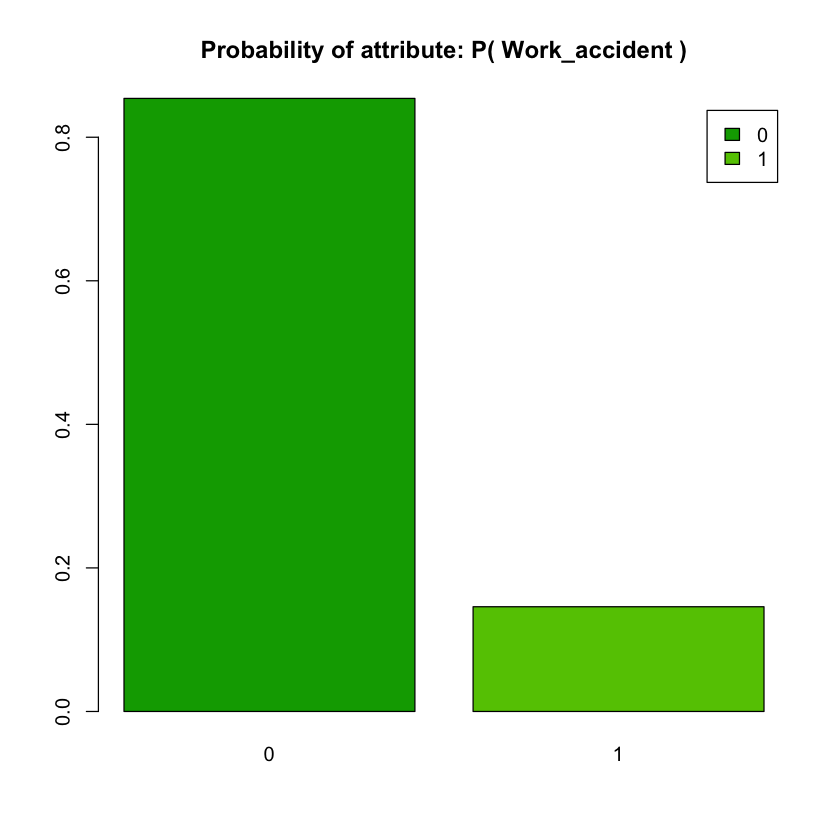

department
 accounting          hr          IT  management   marketing product_mng 
     0.0517      0.0503      0.0825      0.0420      0.0551      0.0608 
      RandD       sales     support   technical 
     0.0524      0.2790      0.1481      0.1781 


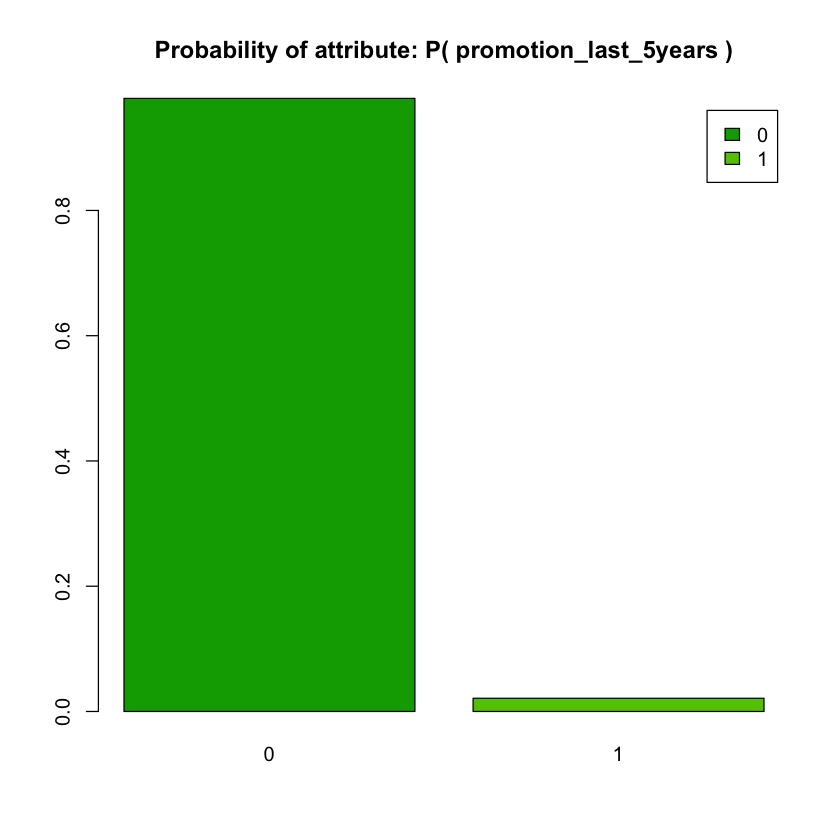

salary
  high    low medium 
0.0790 0.4885 0.4325 


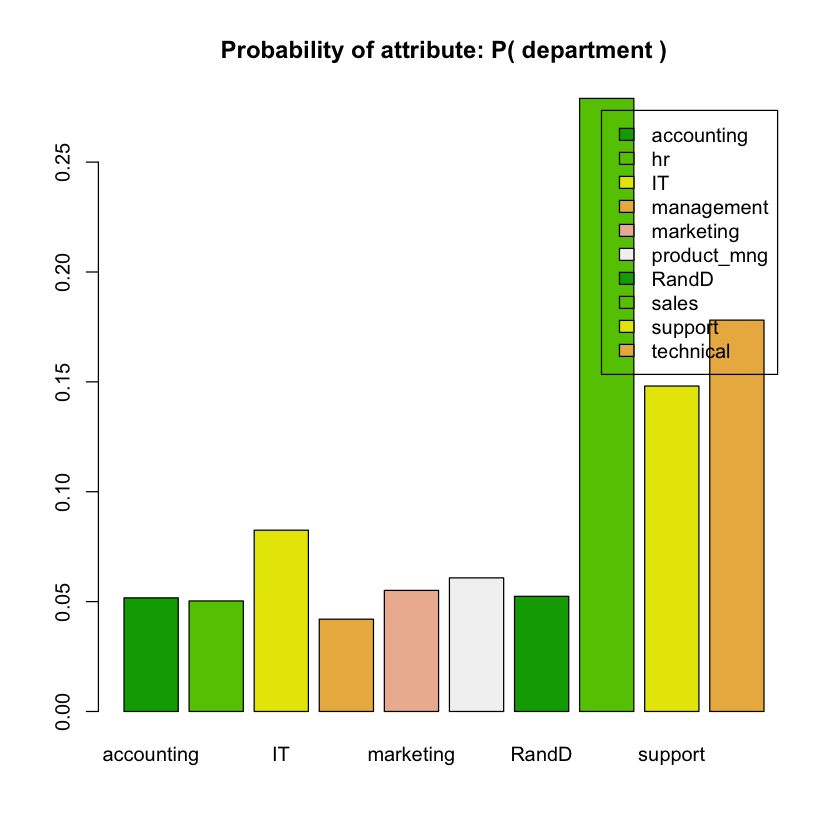

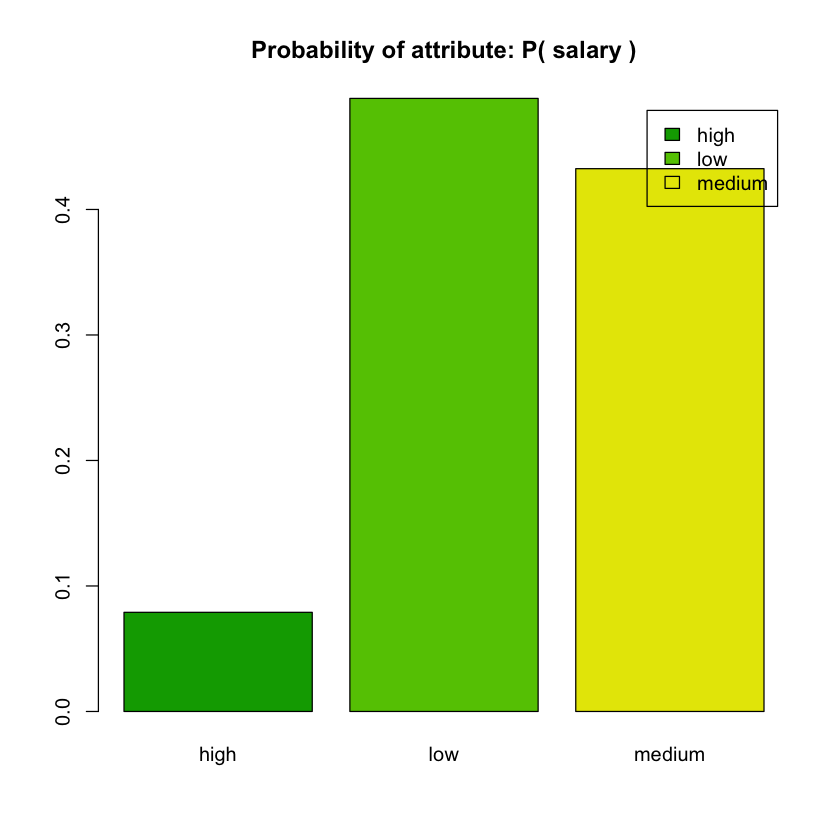

In [2]:
readFile <- function(filename, separator, hasHeader) {
    read.table (file=filename,sep=separator, header=hasHeader)    
}


allAttributesProbability <- function(datasetFile, separator, hasHeader ,indexTargetVariable,indexesQualitativeColumns,indexesUselessColumns) {
    data <- readFile(datasetFile, separator, hasHeader)
    
    for(index in indexesQualitativeColumns ){
        if (index == indexTargetVariable) next
        P.f <- prop.table(table(data[index]))
        print(P.f)
        barplot(P.f, legend = TRUE, col = terrain.colors(6), main = paste("Probability of attribute: P(", names(data)[index], ")"))
    }
}

allAttributesProbability("HR_prediction-all.csv", ",", T, 8, list(7,9,10,11), 1)

             left
Work_accident          0          1
            0 0.73492565 0.26507435
            1 0.91980809 0.08019191
                     left
promotion_last_5years          0          1
                    0 0.75799367 0.24200633
                    1 0.94312796 0.05687204


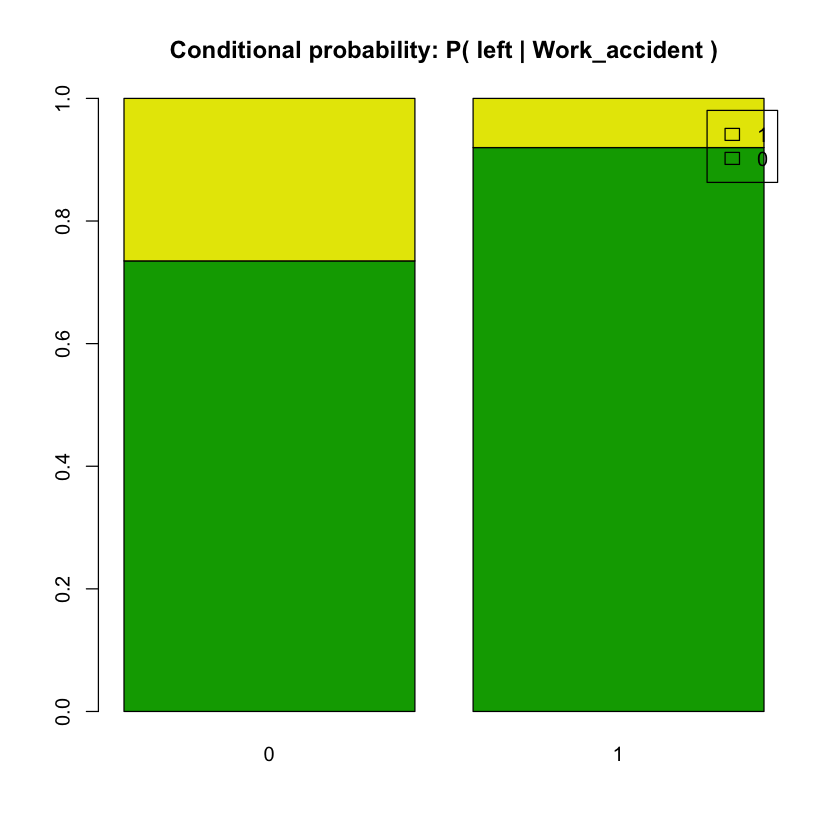

             left
department            0         1
  accounting  0.7272727 0.2727273
  hr          0.7335984 0.2664016
  IT          0.7793939 0.2206061
  management  0.8452381 0.1547619
  marketing   0.7676951 0.2323049
  product_mng 0.7976974 0.2023026
  RandD       0.8587786 0.1412214
  sales       0.7494624 0.2505376
  support     0.7461175 0.2538825
  technical   0.7422796 0.2577204


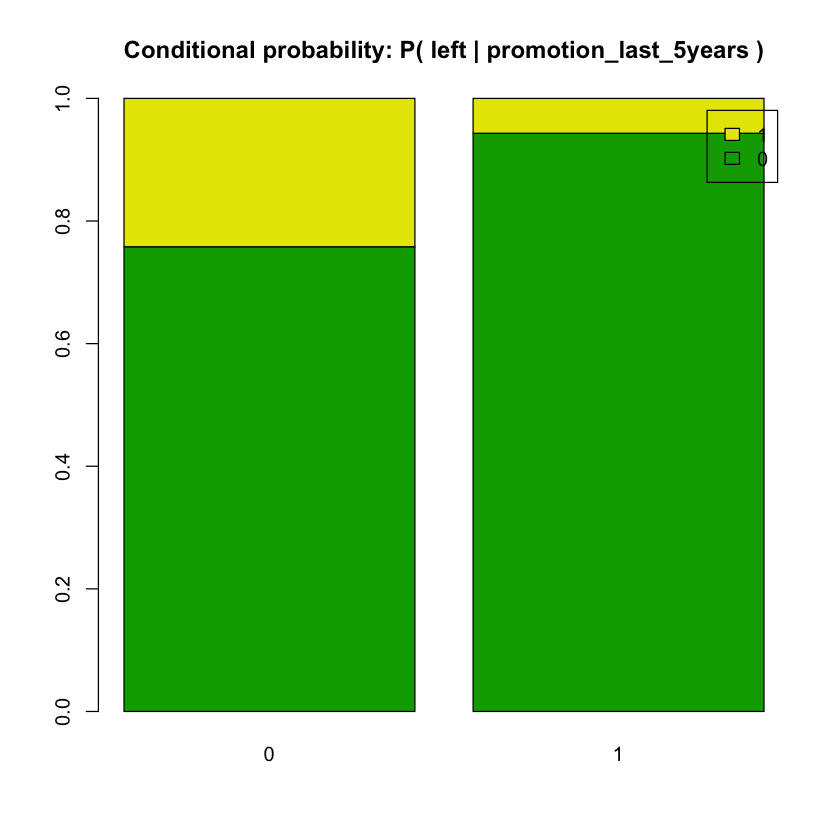

        left
salary            0          1
  high   0.93924051 0.06075949
  low    0.70030706 0.29969294
  medium 0.79907514 0.20092486


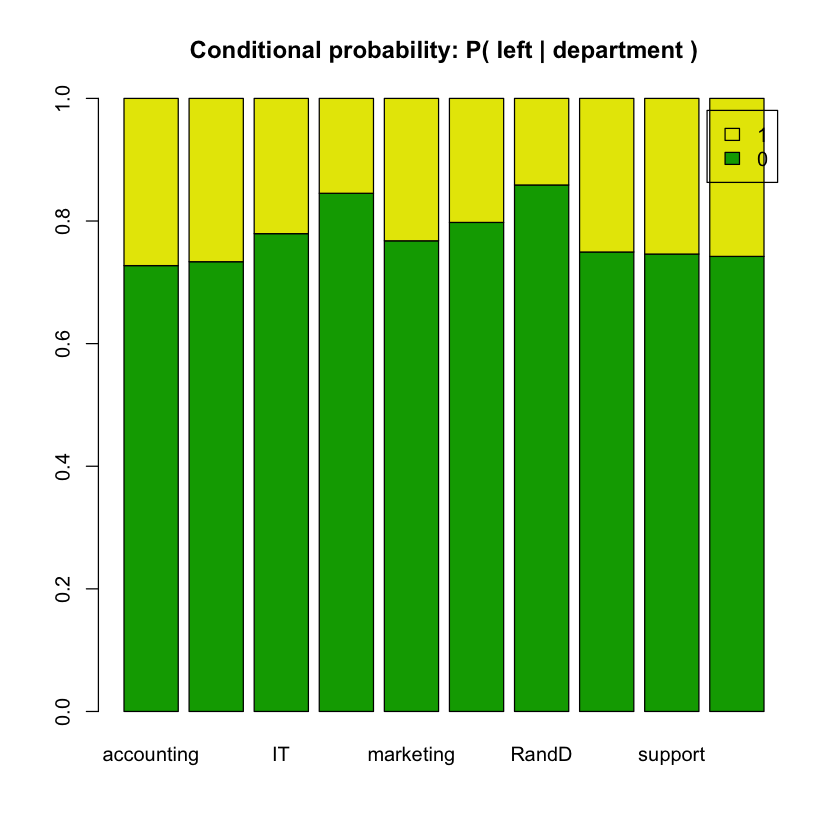

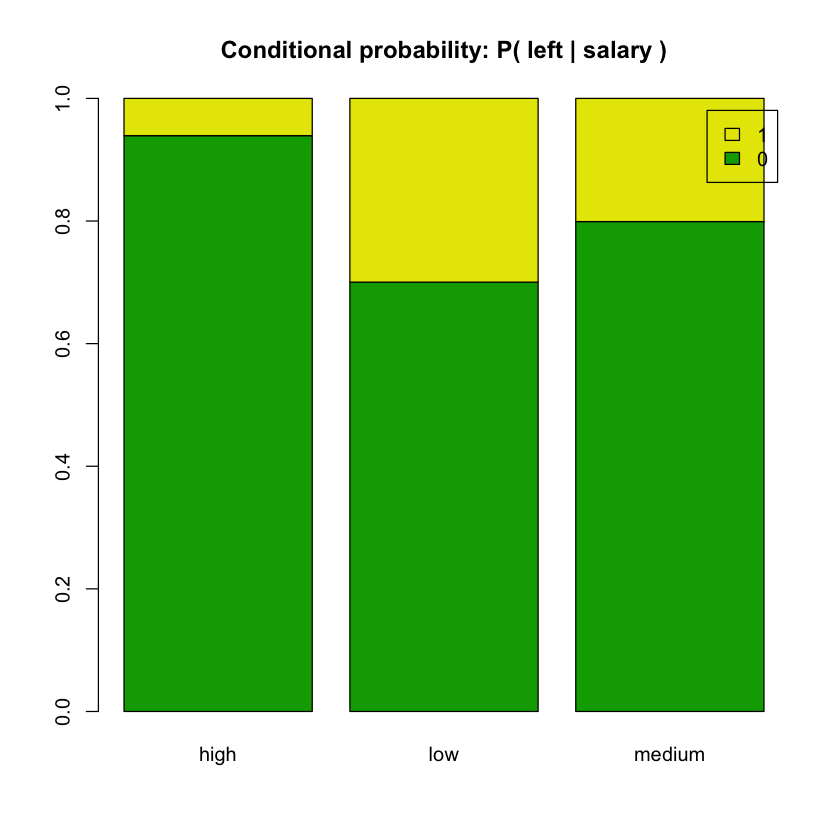

In [3]:
QualitativeAttrsTheory <- function(datasetFile, separator, hasHeader, indexTargetVariable, indexFvariable) {
    data <- readFile(datasetFile, separator, hasHeader)
    jointProbability <- prop.table(table(data[, c(indexTargetVariable, indexFvariable)]))
    print(jointProbability)
    barplot(t(jointProbability), legend.text = T, col = terrain.colors(5), main = "Joint probability P(left, salary)")
    return(jointProbability)
}

CondProbability <- function(datasetFile, separator, hasHeader ,indexTargetVariable,indexesQualitativeColumns,indexesUselessColumns) {
    data <- readFile(datasetFile, separator, hasHeader)
    targetName <- names(data)[indexTargetVariable]

    for(index in indexesQualitativeColumns){
        if (index == indexTargetVariable) next
        conditionalProbability <- prop.table(table(data[,c(index,indexTargetVariable)]),1)
        print(conditionalProbability)
        barplot(t(conditionalProbability), legend.text = T, col = terrain.colors(5),  main=paste("Conditional probability: P(", targetName , "|" , names(data)[index], ")"),)
    }
}

CondProbability("HR_prediction-all.csv", ",", T, 8, list(7,9,10,11), 1)

    promotion_last_5years
left      0      1
   0 0.7420 0.0199
   1 0.2369 0.0012


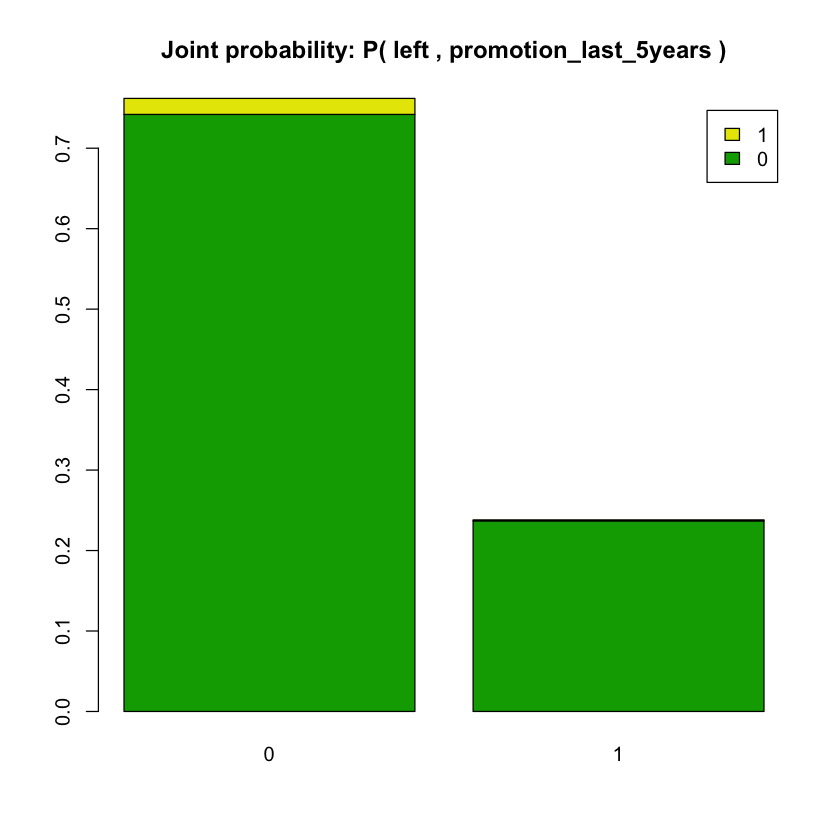

In [12]:
QualitativeAttrsTheory <- function(datasetFile, separator, hasHeader, indexTargetVariable, indexFvariable) {
    data <- readFile(datasetFile, separator, hasHeader)
    jointProbability <- prop.table(table(data[, c(indexTargetVariable, indexFvariable)]))
    print(jointProbability)
    targetName <- names(data)[indexTargetVariable]
    Fvariable <- names(data) [indexFvariable]
    barplot(t(jointProbability), legend.text = T, col = terrain.colors(5), main =paste( "Joint probability: P(", targetName, ",", Fvariable, ")"))
    return(jointProbability)
    reutrn(colSums(P_joint))
    return(rowSums(P_joint))
    
}

P_joint <- QualitativeAttrsTheory("HR_prediction-all.csv", ",", TRUE, 8, 9)



    promotion_last_5years
left      0      1
   0 0.7420 0.0199
   1 0.2369 0.0012


0      1 
0.9789 0.0211

0      1 
0.7619 0.2381

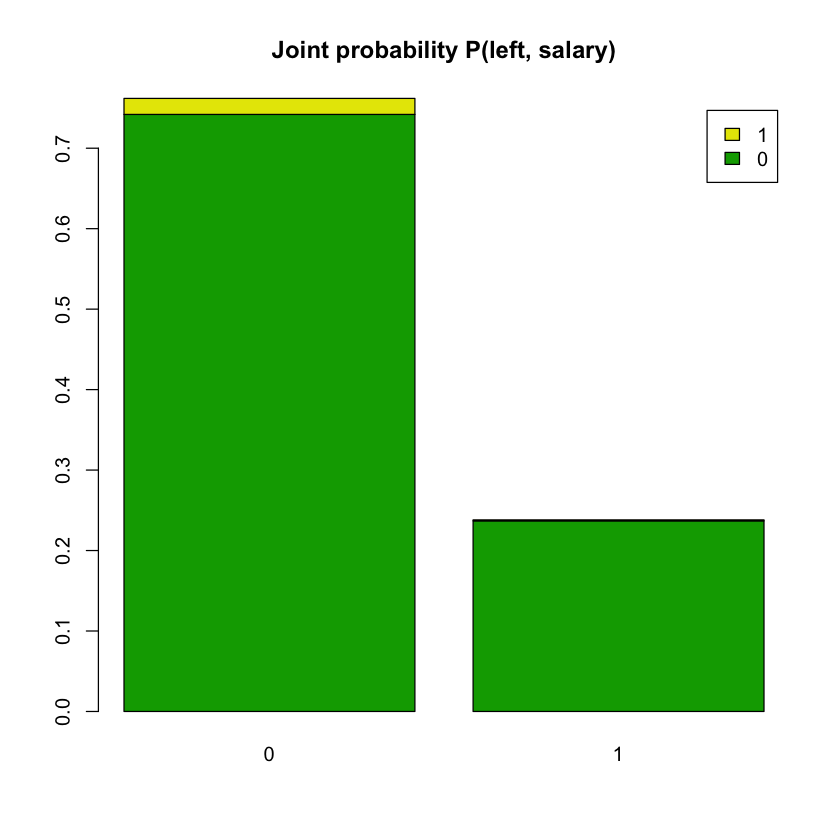

In [85]:
P_joint <- QualitativeAttrsTheory("HR_prediction-all.csv", ",", TRUE, 8, 9)
promo <- colSums(P_joint)
left <- rowSums(P_joint)
print(promo)
print(left)

    promotion_last_5years
left      0      1
   0 0.7420 0.0199
   1 0.2369 0.0012
    promotion_last_5years
left           0           1
   0  0.75799367  0.02032894
   1 11.22748815  0.05687204
    promotion_last_5years
left           0           1
   0 0.973881087 0.026118913
   1 0.994960101 0.005039899


0           1 
11.98548182  0.07720098

0 1 
1 1

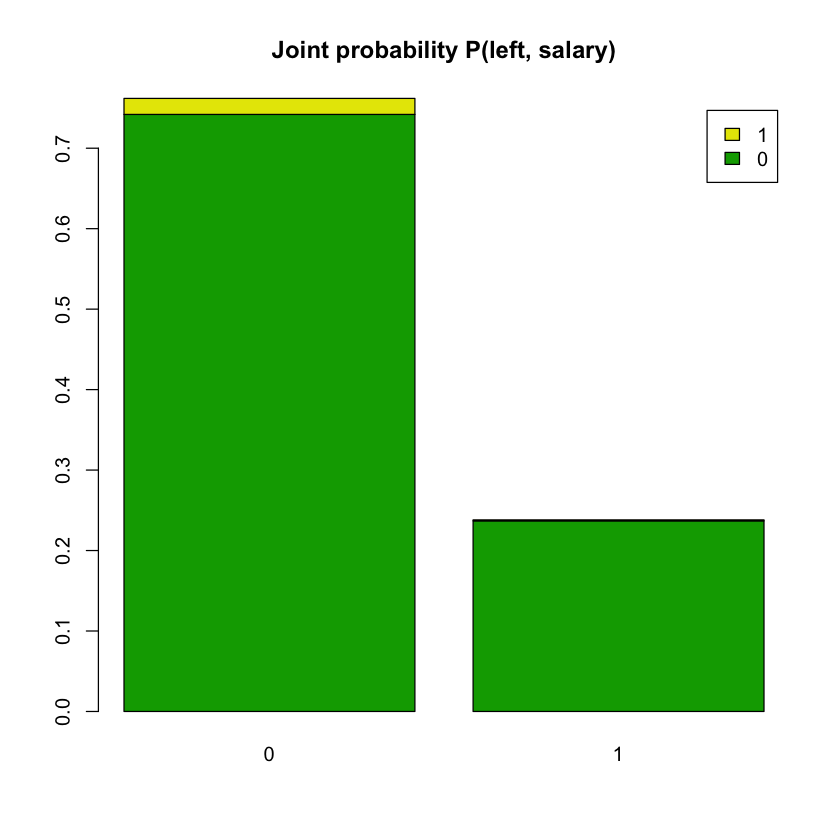

In [94]:
P_joint <- QualitativeAttrsTheory("HR_prediction-all.csv", ",", TRUE, 8, 9)
P_left_promo <- P_joint/colSums(P_joint)
P_promo_left <- P_joint/rowSums(P_joint)
print(P_left_promo)
print(P_promo_left)
colSums(P_left_promo)
rowSums(P_promo_left)